# 01 — Data Understanding, Integrity Audit & Selection-Bias Discovery (`data-v1`)

This notebook audits the **Cloud Workload Forecasting Challenge (`data-v1`)** release derived from Microsoft Azure Public Dataset V2. We verify file checksums, schema integrity, sampling cadence, and uncover the structural **cohort selection bias** explaining why `active_vm_count(t) = 10,000` is constant across all 134 five-minute intervals.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cwfc.io import load_cpu_readings, load_vm_metadata
from cwfc.quality import compute_data_quality_report
from cwfc.policy import compute_fleet_core_capacity

DATA_DIR = Path('../challenge_data')
readings = load_cpu_readings(DATA_DIR)
metadata = load_vm_metadata(DATA_DIR)
print(f'Readings shape: {readings.shape}, Metadata shape: {metadata.shape}')
readings.head()

Readings shape: (1340000, 5), Metadata shape: (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


## 1. Automated Data Quality & Physical Invariant Audit
We run `compute_data_quality_report` to verify completeness, cadence regularity (`dt = 300s`), duplicate `(timestamp, vm_id)` pairs, and physical bounds (`0 <= min_cpu <= avg_cpu <= max_cpu <= 100`).

In [2]:
dq = compute_data_quality_report(readings, metadata)
print(json.dumps(dq, indent=2))

{
  "total_rows": 1340000,
  "unique_vms": 10000,
  "unique_timestamps": 134,
  "timestamp_min": 0,
  "timestamp_max": 39900,
  "cadence_diffs": {
    "300": 133
  },
  "is_regular_cadence": true,
  "missing_values_cpu": {
    "min_cpu": 0,
    "avg_cpu": 0,
    "max_cpu": 0
  },
  "duplicate_vm_timestamp_pairs": 0,
  "obs_per_vm_min": 134,
  "obs_per_vm_max": 134,
  "is_balanced_panel": true,
  "active_vm_count_min": 10000,
  "active_vm_count_max": 10000,
  "is_constant_active_vms": true,
  "cpu_bounds": {
    "min_cpu": {
      "min": 0.0,
      "p25": 1.4879789888412092,
      "median": 3.2279961997412627,
      "mean": 6.156477978208739,
      "p75": 5.331087280121448,
      "p95": 22.825925474106707,
      "max": 99.28158160997798
    },
    "avg_cpu": {
      "min": 0.007158921626865188,
      "p25": 2.4770598636558034,
      "median": 5.105132868038028,
      "mean": 9.388100729421827,
      "p75": 9.616714848443115,
      "p95": 37.132946878634996,
      "max": 99.4880266539945

## 2. Structural Discovery: Cohort Selection Bias in `active_vm_count`
Every single VM in `data-v1` has `timestamp_vm_created == 0` and `timestamp_vm_deleted >= 40,500` (10 minutes *after* the holdout window ends at `39,900s`). Consequently, all 10,000 VMs remain active throughout both the 110-step training window (`0..32,700s`) and the 24-step holdout window (`33,000..39,900s`).

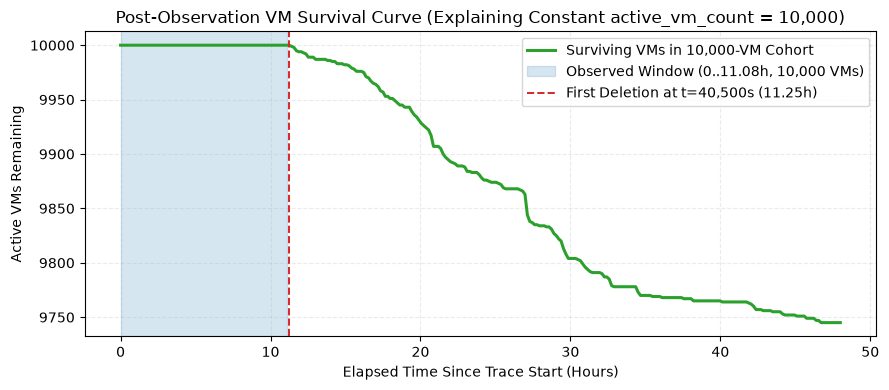

In [3]:
del_ts = np.sort(metadata['timestamp_vm_deleted'].to_numpy(dtype=float)) / 3600.0
grid_h = np.linspace(0, 48, 300)
alive = [(del_ts > h).sum() for h in grid_h]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid_h, alive, color='#2ca02c', lw=2.2, label='Surviving VMs in 10,000-VM Cohort')
ax.axvspan(0, 39900 / 3600.0, color='#1f77b4', alpha=0.18, label='Observed Window (0..11.08h, 10,000 VMs)')
ax.axvline(40500 / 3600.0, color='#d62728', ls='--', lw=1.4, label='First Deletion at t=40,500s (11.25h)')
ax.set_title('Post-Observation VM Survival Curve (Explaining Constant active_vm_count = 10,000)')
ax.set_xlabel('Elapsed Time Since Trace Start (Hours)')
ax.set_ylabel('Active VMs Remaining')
ax.legend()
ax.grid(alpha=0.25, ls='--')
plt.tight_layout()
plt.show()

## 3. Fleet Metadata Breakdown & Provisioned vCore Capacity
Mapping `virtual_core_bucket` (`2, 4, 8, 24, >24 -> 32`) gives a total fleet capacity of **28,388 virtual cores**.

In [4]:
cap_df = compute_fleet_core_capacity(readings, metadata)
summary = pd.DataFrame({
    'vm_category_counts': pd.Series(dq['category_counts']),
})
print('Total provisioned vCores:', int(cap_df['total_provisioned_cores'].iloc[0]))
print('Mean core-weighted CPU (%):', round(float(cap_df['core_weighted_cpu_utilization'].mean()), 3))
print('Mean peak-to-avg core demand ratio:', round(float(cap_df['peak_to_avg_ratio'].mean()), 3))
display(metadata['vm_category'].value_counts().to_frame('vm_count'))
display(metadata['virtual_core_bucket'].value_counts().to_frame('vm_count'))

Total provisioned vCores: 28396
Mean core-weighted CPU (%): 9.291
Mean peak-to-avg core demand ratio: 2.013


,vm_count
vm_category,
Delay-insensitive,6180
Interactive,3091
Unknown,729


,vm_count
virtual_core_bucket,
2,7534
4,1908
8,486
24,62
>24,10
